<a href="https://colab.research.google.com/github/Theresa-Gao-0529/MSSP607/blob/main/Participation_Activity_Week_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from pathlib import Path
from urllib.parse import quote
import io
from urllib.request import urlopen
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
# GitHub is the source of truth: this works in both Colab and regular Jupyter.
owner = 'Theresa-Gao-0529'
repository = 'MSSP607'
branch = 'main'
data_path = 'data/week12/Student Performance Data (2).csv'
repo_url = f'https://github.com/{owner}/{repository}'
raw_url = (f'https://raw.githubusercontent.com/{owner}/{repository}/'
            f'{branch}/{quote(data_path, safe="/")}')
with urlopen(raw_url, timeout=30) as response:
    df = pd.read_csv(io.BytesIO(response.read()))
print(f'Loaded from GitHub: {raw_url}')
print(f'Dataset: {df.shape[0]} students × {df.shape[1]} columns')
df.head()


Loaded from GitHub: https://raw.githubusercontent.com/Theresa-Gao-0529/MSSP607/main/data/week12/Student%20Performance%20Data%20%282%29.csv
Dataset: 1000 students × 10 columns


,gender,race/ethnicity,parental level of education,lunch,math score,reading score,writing score,total score,test preparation course,admission prospect
0,female,group B,bachelor's degree,standard,72,72,74,218,none,medium
1,female,group C,some college,standard,69,90,88,247,completed,high
2,female,group B,master's degree,standard,90,95,93,278,none,high
3,male,group A,associate's degree,free/reduced,47,57,44,148,none,low
4,male,group C,some college,standard,76,78,75,229,none,high


## 1. Check the data and define the test




In [2]:
required = {'gender', 'test preparation course', 'total score'}
assert required.issubset(df.columns), f'Missing columns: {required - set(df.columns)}'
print(df[list(required)].isna().sum())

prepared = df.loc[(df['gender'] == 'male') & (df['test preparation course'] == 'completed'), 'total score'].dropna()
not_prepared = df.loc[(df['gender'] == 'male') & (df['test preparation course'] == 'none'), 'total score'].dropna()
print(f'Male, completed: n={len(prepared)}, mean={prepared.mean():.2f}, SD={prepared.std(ddof=1):.2f}')
print(f'Male, none:      n={len(not_prepared)}, mean={not_prepared.mean():.2f}, SD={not_prepared.std(ddof=1):.2f}')


gender                     0
test preparation course    0
total score                0
dtype: int64
Male, completed: n=174, mean=212.34, SD=39.60
Male, none:      n=308, mean=189.13, SD=39.59


## 2. Welch two-sample t-test




In [3]:
test = stats.ttest_ind(prepared, not_prepared, equal_var=False, alternative='two-sided')
difference = prepared.mean() - not_prepared.mean()
# Welch-Satterthwaite degrees of freedom and a 95% CI for the difference
a, b = prepared.to_numpy(), not_prepared.to_numpy()
se = np.sqrt(a.var(ddof=1)/len(a) + b.var(ddof=1)/len(b))
df_welch = (a.var(ddof=1)/len(a) + b.var(ddof=1)/len(b))**2 / ((a.var(ddof=1)/len(a))**2/(len(a)-1) + (b.var(ddof=1)/len(b))**2/(len(b)-1))
ci = difference + np.array([-1, 1]) * stats.t.ppf(0.975, df_welch) * se
print(f't = {test.statistic:.3f}, df = {df_welch:.1f}, two-sided p = {test.pvalue:.3g}')
print(f'Mean difference (completed − none) = {difference:.2f} points')
print(f'95% CI for mean difference = [{ci[0]:.2f}, {ci[1]:.2f}]')
alpha = 0.05
print('Decision:', 'Reject H0' if test.pvalue < alpha else 'Fail to reject H0')


t = 6.181, df = 359.0, two-sided p = 1.73e-09
Mean difference (completed − none) = 23.21 points
95% CI for mean difference = [15.83, 30.60]
Decision: Reject H0


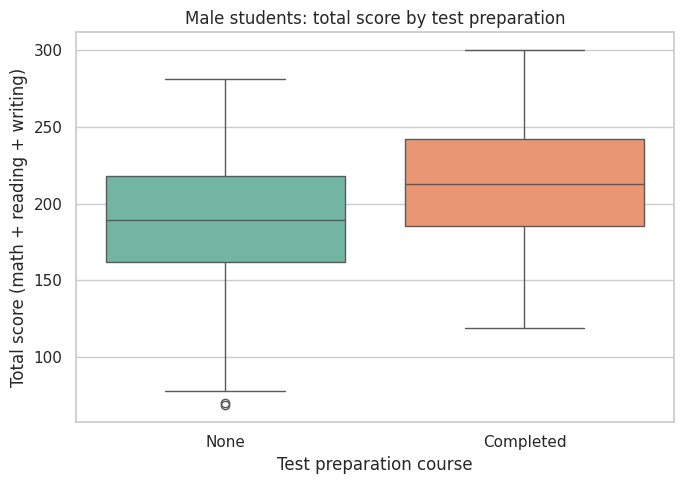

In [4]:
plot_df = df.loc[df['gender'] == 'male'].copy()
plot_df['Preparation'] = plot_df['test preparation course'].map({'completed':'Completed', 'none':'None'})
plt.figure(figsize=(7, 5))
sns.boxplot(data=plot_df, x='Preparation', y='total score', hue='Preparation', legend=False, palette='Set2')
plt.title('Male students: total score by test preparation')
plt.xlabel('Test preparation course')
plt.ylabel('Total score (math + reading + writing)')
plt.tight_layout()
plt.show()


## 3. Other differences of interest



In [5]:
def welch_summary(data, group_col, group_a, group_b, label):
    x = data.loc[data[group_col] == group_a, 'total score'].dropna()
    y = data.loc[data[group_col] == group_b, 'total score'].dropna()
    res = stats.ttest_ind(x, y, equal_var=False)
    print(f'{label}: {group_a} n={len(x)}, mean={x.mean():.2f}; {group_b} n={len(y)}, mean={y.mean():.2f}; difference={x.mean()-y.mean():.2f}; t={res.statistic:.2f}, p={res.pvalue:.3g}')

welch_summary(df, 'test preparation course', 'completed', 'none', 'All students: preparation')
welch_summary(df, 'gender', 'female', 'male', 'Gender')
welch_summary(df, 'lunch', 'standard', 'free/reduced', 'Lunch')

for col in ['race/ethnicity', 'parental level of education']:
    groups = [g['total score'].dropna().to_numpy() for _, g in df.groupby(col, observed=True)]
    res = stats.f_oneway(*groups)
    means = df.groupby(col, observed=True)['total score'].mean().sort_values(ascending=False)
    print(f'\n{col}: one-way ANOVA F={res.statistic:.2f}, p={res.pvalue:.3g}')
    display(means.rename('mean total score').to_frame().round(2))


All students: preparation: completed n=358, mean=218.01; none n=642, mean=195.12; difference=22.89; t=8.59, p=4.43e-17
Gender: female n=518, mean=208.71; male n=482, mean=197.51; difference=11.20; t=4.18, p=3.19e-05
Lunch: standard n=645, mean=212.51; free/reduced n=355, mean=186.60; difference=25.91; t=9.32, p=1.58e-19

race/ethnicity: one-way ANOVA F=9.10, p=3.23e-07


,mean total score
race/ethnicity,
group E,218.26
group D,207.54
group C,201.39
group B,196.41
group A,188.98



parental level of education: one-way ANOVA F=10.75, p=4.38e-10


,mean total score
parental level of education,
master's degree,220.80
bachelor's degree,215.77
associate's degree,208.71
some college,205.43
some high school,195.32
high school,189.29


## Interpretation and conclusion

For male students, the completed-preparation group averaged about **212.34** total points (n=174), compared with **189.13** (n=308) for the group with no preparation course. Welch's test gives **t ≈ 6.18**, **p ≈ 1.73 × 10⁻⁹**, with a mean difference of about **23.21 points** (95% CI approximately **15.83 to 30.61**). Since p < 0.05, the null hypothesis is rejected: the data provide strong evidence of a difference in mean total scores between these two male groups.

Other notable patterns: across all students, the preparation-completed group has a higher mean total score; females average higher than males in this dataset; and students with standard lunch average higher than those with free/reduced lunch. The ANOVAs also indicate variation in mean total score across race/ethnicity groups and parental education categories. These are descriptive associations, not proof of causes; group differences may reflect other factors. The additional comparisons are exploratory and should be interpreted cautiously because multiple tests were run.
